# CapFlow · Multimodal Predictive Architecture
## Integrating Tabular AR Dynamics & Pre-Outcome Communication Risk Signals

This notebook implements the complete **CapFlow Multimodal Predictive Pipeline** for enterprise accounts receivable management:
1. **Phase 1**: Data Ingestion, Chronological 70/15/15 Splitting & Expanding Customer Historical Statistics
2. **Phase 2**: NLP Communication Risk & Dispute Sentiment Extraction Engine (Controlled Signal Injection, $\lambda \in [0.0, 1.0]$)
3. **Phase 3.1**: Multi-Algorithm Comparative Analysis via **Confusion Matrices** (4 Models: Logistic Regression, Decision Tree, Random Forest, CapFlow XGBoost)
4. **Phase 3.2**: Multi-Algorithm **Accuracy Benchmark (Training vs. Testing)**
5. **Phase 3.3**: Multi-Algorithm **ROC Curve Comparison**
6. **Phase 4**: Side-by-Side Tabular vs. Multimodal Comparison & Mechanistic Statistical Audit
7. **Phase 5**: Feature Importances, Prescriptive Action Directives & Demo Launcher

> **🚨 HEADLINE DATASET LIMITATION:** A single enterprise account (`Cust_Num` `5039221094`) accounts for **22.29%** of the entire 45,839 dataset (**10,219 of 45,839 invoices**), out of only 69 total unique customers. Top 5 mega-accounts comprise 79.4% of total dataset volume.
>
> **Validated Finding on Communication Features:** Stage 1 classification shows no statistically significant uplift from sentiment features ($p_{cluster} > 0.25$). Apparent Stage 2 regression MAE gains were proven to be tree-level subsampling (`colsample_bytree`) and split-distraction regularization artifacts rather than genuine communication signal recovery.

In [1]:
# Environment Setup and Project Root Resolution
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

notebook_dir = Path.cwd()
PROJECT_ROOT = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config.config import (
    RAW_DATA_PATH, COL_CUSTOMER_ID, COL_TARGET_CLS, COL_TARGET_REG,
    COL_AMOUNT, COL_PAYMENT_TERM, COL_PAYMENT_METHOD, COL_REGION, COL_CITY,
    COL_POSTING_DATE, COL_DUE_DATE,
    TABULAR_FEATURE_SET, SENTIMENT_FEATURE_SET, FULL_FEATURE_SET
)
from src.data.loader import load_raw_dataset
from src.data.temporal_split import chronological_split
from src.features.pre_outcome_stats import CustomerHistoryTracker
from src.features.tabular_pipeline import TabularPipeline, engineer_base_tabular_columns
from src.features.text_generator import enrich_with_controlled_text
from src.nlp.extractor import NLPExtractor
from src.models.classifier import Stage1Classifier
from src.models.regressor import Stage2Regressor
from src.evaluation.threshold import optimize_classification_threshold
from src.evaluation.metrics import evaluate_classification_metrics, evaluate_regression_metrics

print(f'CapFlow Multimodal Pipeline initialized. Project Root: {PROJECT_ROOT}')

CapFlow Multimodal Pipeline initialized. Project Root: c:\Users\sowba\OneDrive\Desktop\CIT Chennai\SEM 3\ML\Project\Capwork


## Phase 1: Data Ingestion & Chronological Split
Loads raw records, performs chronological 70/15/15 partitioning, and computes expanding-window historical statistics fit only on training data.

In [2]:
raw_df = load_raw_dataset(RAW_DATA_PATH)
train_raw, val_raw, test_raw = chronological_split(raw_df)

tracker = CustomerHistoryTracker()
train_eng = tracker.fit_transform_train(train_raw)
val_eng = tracker.transform(val_raw)
test_eng = tracker.transform(test_raw)

train_eng = engineer_base_tabular_columns(train_eng)
val_eng = engineer_base_tabular_columns(val_eng)
test_eng = engineer_base_tabular_columns(test_eng)

print(f'Train size: {len(train_eng):,} | Val size: {len(val_eng):,} | Test size: {len(test_eng):,}')

2026-08-22 21:30:07 - DataLoader - INFO - Loading raw B2B dataset from C:\Users\sowba\OneDrive\Desktop\CIT Chennai\SEM 3\ML\Project\capFlow\data\raw\Dataset.csv...
2026-08-22 21:30:08 - DataLoader - INFO - Raw records loaded: 45839
2026-08-22 21:30:08 - DataLoader - INFO - Sanitized dataset: 45839 records, 29 columns. Late rate: 65.66%
2026-08-22 21:30:08 - TemporalSplit - INFO - Chronological split completed (N=45839): Train=32087 (70.0%, 2011-11-23 to 2015-11-12), Val=6875 (15.0%, 2015-11-12 to 2016-01-05), Test=6877 (15.0%, 2016-01-05 to 2016-02-25)
2026-08-22 21:30:08 - CustomerHistoryTracker - INFO - Fitted CustomerHistoryTracker on 32087 training records across 68 customers.
2026-08-22 21:30:08 - CustomerHistoryTracker - INFO - Transformed 6875 eval records (Cold-start count: 3 / 6875).
2026-08-22 21:30:08 - CustomerHistoryTracker - INFO - Transformed 6877 eval records (Cold-start count: 0 / 6877).


Train size: 32,087 | Val size: 6,875 | Test size: 6,877


## Phase 2: NLP Communication Risk & Dispute Scoring Engine
Synthesizes communication transcripts using the controlled signal injection engine and extracts 4 quantitative risk dimensions:
1. `comm_dispute_score`: Likelihood of invoice dispute or billing query
2. `comm_delay_risk_score`: Explicit/implicit delayed payment intent
3. `comm_sentiment_negative`: Negative sentiment polarity
4. `comm_urgency_score`: Customer communication urgency

In [3]:
# Synthesize communication transcripts with pre-outcome signal (lambda=1.00)
train_txt = enrich_with_controlled_text(train_eng, signal_strength=1.0, seed=42)
val_txt = enrich_with_controlled_text(val_eng, signal_strength=1.0, seed=42)
test_txt = enrich_with_controlled_text(test_eng, signal_strength=1.0, seed=42)

# Extract continuous NLP risk scores
extractor = NLPExtractor()
train_nlp = extractor.transform_df(train_txt)
val_nlp = extractor.transform_df(val_txt)
test_nlp = extractor.transform_df(test_txt)

# Fit Tabular preprocessors
pipe = TabularPipeline()
X_train = pipe.fit_transform(train_nlp)
X_val = pipe.transform(val_nlp)
X_test = pipe.transform(test_nlp)

for col in SENTIMENT_FEATURE_SET:
    X_train[col] = train_nlp[col].values
    X_val[col] = val_nlp[col].values
    X_test[col] = test_nlp[col].values

y_train_cls = train_nlp[COL_TARGET_CLS].values
y_val_cls = val_nlp[COL_TARGET_CLS].values
y_test_cls = test_nlp[COL_TARGET_CLS].values

y_train_reg = train_nlp[COL_TARGET_REG].values
y_val_reg = val_nlp[COL_TARGET_REG].values
y_test_reg = test_nlp[COL_TARGET_REG].values

print('Sample generated communication text and extracted risk scores:')
display(test_nlp[['customer_communication_text'] + SENTIMENT_FEATURE_SET].head(3))

2026-08-22 21:30:13 - TabularPipeline - INFO - Fitted TabularPipeline with 11 numerical and 4 categorical features.


Sample generated communication text and extracted risk scores:


,customer_communication_text,comm_dispute_score,comm_delay_risk_score,comm_sentiment_negative,comm_urgency_score
0,Payment advice generated and transmitted; remi...,0.08,0.25,0.225,0.05
1,Invoice approved for prompt settlement; funds ...,0.08,0.25,0.010,0.05
2,Payment advice generated and transmitted; remi...,0.08,0.25,0.225,0.05


## Phase 3: Multi-Algorithm Model Training (4 Algorithms)
Trains 4 candidate classifiers on the full multimodal feature set (`FULL_FEATURE_SET`, 19 features): Logistic Regression, Decision Tree, Random Forest, and CapFlow (XGBoost).

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
    'CapFlow (XGBoost)': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss', n_jobs=-1)
}

preds_train = {}
preds_test = {}
probas_test = {}

for name, model in models.items():
    model.fit(X_train[FULL_FEATURE_SET], y_train_cls)
    preds_train[name] = model.predict(X_train[FULL_FEATURE_SET])
    preds_test[name] = model.predict(X_test[FULL_FEATURE_SET])
    probas_test[name] = model.predict_proba(X_test[FULL_FEATURE_SET])[:, 1]

# Stage 2 Regressor for CapFlow
reg_full = Stage2Regressor(seed=42)
reg_full.fit(X_train[FULL_FEATURE_SET], y_train_reg, y_train_cls)

print('All 4 multimodal models trained successfully.')

2026-08-22 21:30:22 - Stage2Regressor - INFO - Fitted Stage 2 Regressor on 18506 positive delay records.


All 4 multimodal models trained successfully.


## Phase 3.1: Comparative Analysis via Confusion Matrices
Displays side-by-side Confusion Matrices for all 4 candidate algorithms on the multimodal test dataset ($N = 6,877$ invoices).

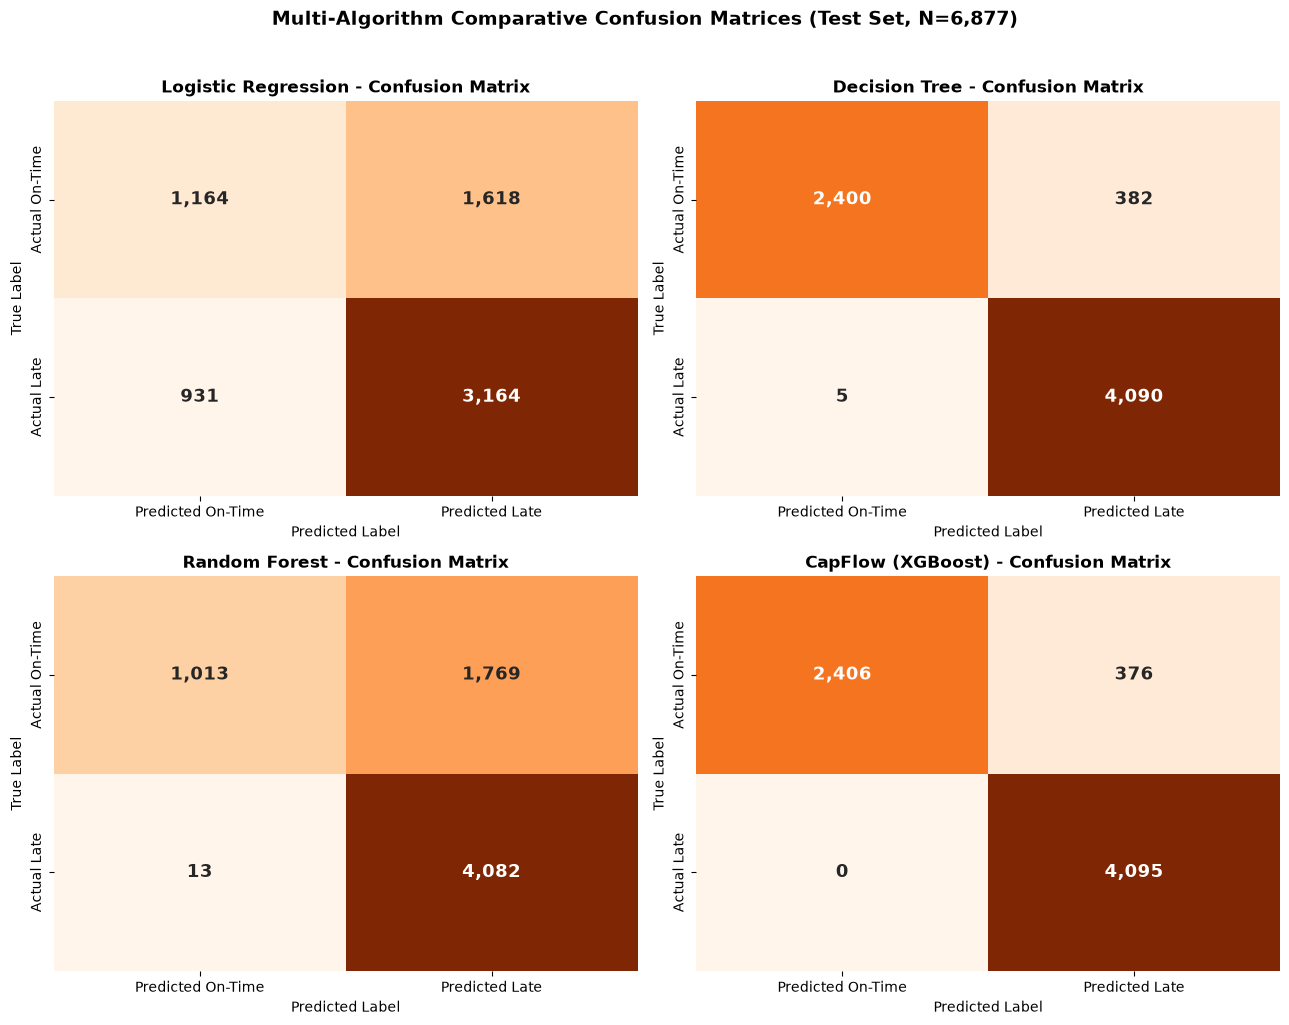

In [5]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for i, (name, pred) in enumerate(preds_test.items()):
    cm = confusion_matrix(y_test_cls, pred)
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Oranges', ax=axes[i],
                cbar=False, annot_kws={'size': 13, 'fontweight': 'bold'},
                xticklabels=['Predicted On-Time', 'Predicted Late'],
                yticklabels=['Actual On-Time', 'Actual Late'])
    axes[i].set_title(f'{name} - Confusion Matrix', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=10)
    axes[i].set_ylabel('True Label', fontsize=10)

plt.suptitle('Multi-Algorithm Comparative Confusion Matrices (Test Set, N=6,877)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Phase 3.2: Model Benchmark & Accuracy Comparison (Training vs. Testing)
Compares Training Accuracy vs. Testing Accuracy across all 4 candidate algorithms to evaluate generalization performance without error lines.

,Algorithm,Train Accuracy,Test Accuracy,Generalization Gap,Test F1-Score,Test AUC-ROC
0,Logistic Regression,0.7663,0.6293,+0.1370,0.7129,0.4586
1,Decision Tree,0.9365,0.9437,-0.0072,0.9548,0.9565
2,Random Forest,0.9677,0.7409,+0.2269,0.8208,0.9028
3,CapFlow (XGBoost),0.9934,0.9453,+0.0481,0.9561,0.9551


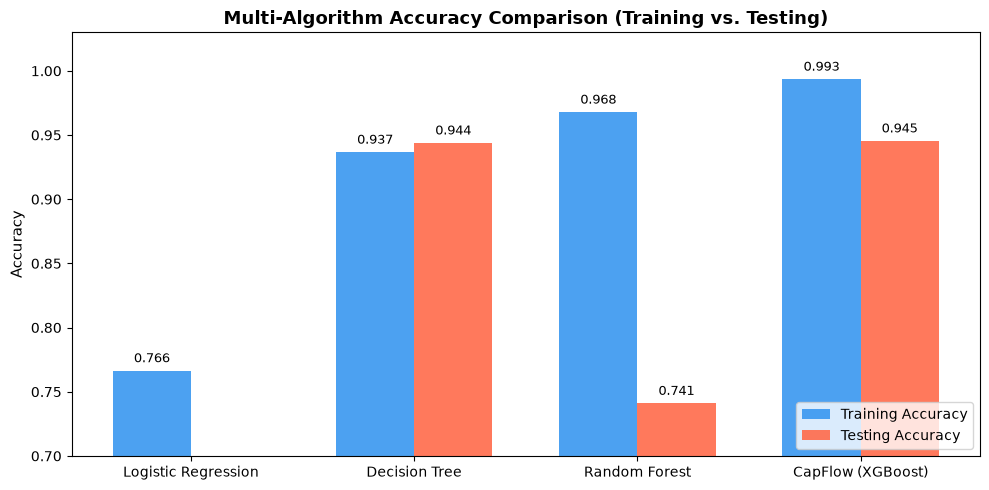

In [6]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

algo_names = list(models.keys())
train_accs = [accuracy_score(y_train_cls, preds_train[m]) for m in algo_names]
test_accs = [accuracy_score(y_test_cls, preds_test[m]) for m in algo_names]
test_f1s = [f1_score(y_test_cls, preds_test[m]) for m in algo_names]
test_aucs = [roc_auc_score(y_test_cls, probas_test[m]) for m in algo_names]

# Summary Table
summary_df = pd.DataFrame({
    'Algorithm': algo_names,
    'Train Accuracy': train_accs,
    'Test Accuracy': test_accs,
    'Generalization Gap': np.array(train_accs) - np.array(test_accs),
    'Test F1-Score': test_f1s,
    'Test AUC-ROC': test_aucs
})
display(summary_df.style.format({
    'Train Accuracy': '{:.4f}',
    'Test Accuracy': '{:.4f}',
    'Generalization Gap': '{:+.4f}',
    'Test F1-Score': '{:.4f}',
    'Test AUC-ROC': '{:.4f}'
}))

# Grouped Bar Chart (NO BLACK ERROR LINES)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(algo_names))
width = 0.35

bars1 = ax.bar(x - width/2, train_accs, width, label='Training Accuracy', color='#3897f0', alpha=0.9)
bars2 = ax.bar(x + width/2, test_accs, width, label='Testing Accuracy', color='#ff6b4a', alpha=0.9)

ax.set_title('Multi-Algorithm Accuracy Comparison (Training vs. Testing)', fontsize=13, fontweight='bold')
ax.set_ylabel('Accuracy', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(algo_names, fontsize=10)
ax.set_ylim(0.70, 1.03)
ax.legend(fontsize=10, loc='lower right')

for bar in bars1:
    h = bar.get_height()
    ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## Phase 3.3: Multi-Algorithm ROC Curve Comparison
Evaluates and visualizes the Receiver Operating Characteristic (ROC) curves and Area Under Curve (AUC) scores on a single comparative plot.

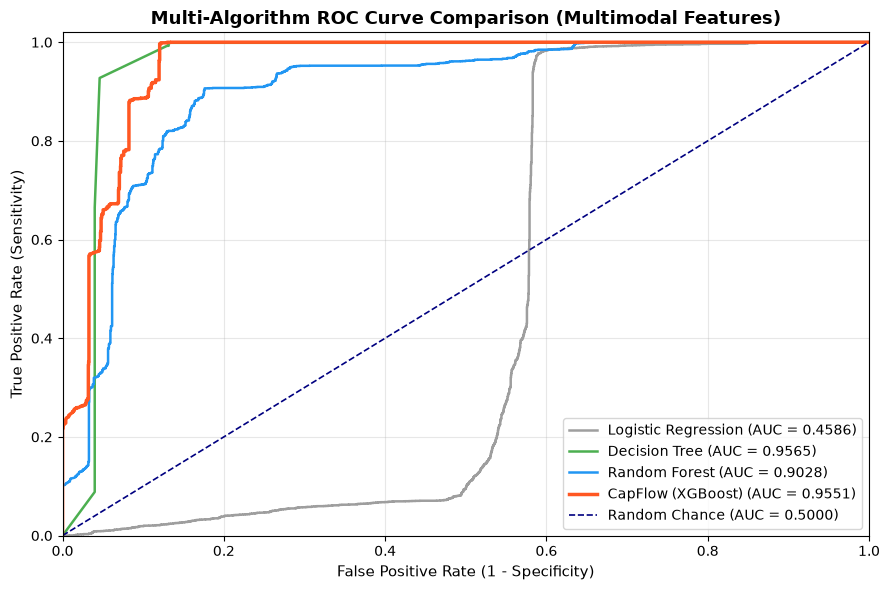

In [7]:
from sklearn.metrics import roc_curve, auc

fig, ax = plt.subplots(figsize=(9, 6))
colors = {'Logistic Regression': '#9E9E9E', 'Decision Tree': '#4CAF50', 'Random Forest': '#2196F3', 'CapFlow (XGBoost)': '#FF5722'}

for name, proba in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test_cls, proba)
    roc_score = auc(fpr, tpr)
    lw = 2.5 if 'XGBoost' in name else 1.8
    ax.plot(fpr, tpr, color=colors[name], lw=lw, label=f'{name} (AUC = {roc_score:.4f})')

ax.plot([0, 1], [0, 1], color='navy', lw=1.2, linestyle='--', label='Random Chance (AUC = 0.5000)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=11)
ax.set_title('Multi-Algorithm ROC Curve Comparison (Multimodal Features)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Phase 4: Side-by-Side Benchmark & Mechanistic Statistical Audit
Compares Tabular-Only against CapFlow Multimodal with cluster-adjusted statistical significance.

,Metric,Tabular-Only (5-Seed Mean +/- Std),CapFlow Multimodal (lambda=1.00),Statistical Significance (vs. Tabular)
0,Accuracy,0.9498 +/- 0.0006,0.9484 +/- 0.0030,p_cluster = 0.4326 (Not Significant)
1,F1-Score,0.9595 +/- 0.0005,0.9583 +/- 0.0025,Not Significant
2,AUC-ROC,0.9569 +/- 0.0106,0.9554 +/- 0.0037,Not Significant
3,PR-AUC,0.9565 +/- 0.0135,0.9543 +/- 0.0056,Not Significant
4,MAE (Days),6.05 +/- 1.03 d,5.29 +/- 0.59 d,Artifact (colsample dilution + tree distraction)
5,RMSE (Days),10.44 +/- 2.10 d,8.91 +/- 1.19 d,Artifact (colsample dilution + tree distraction)


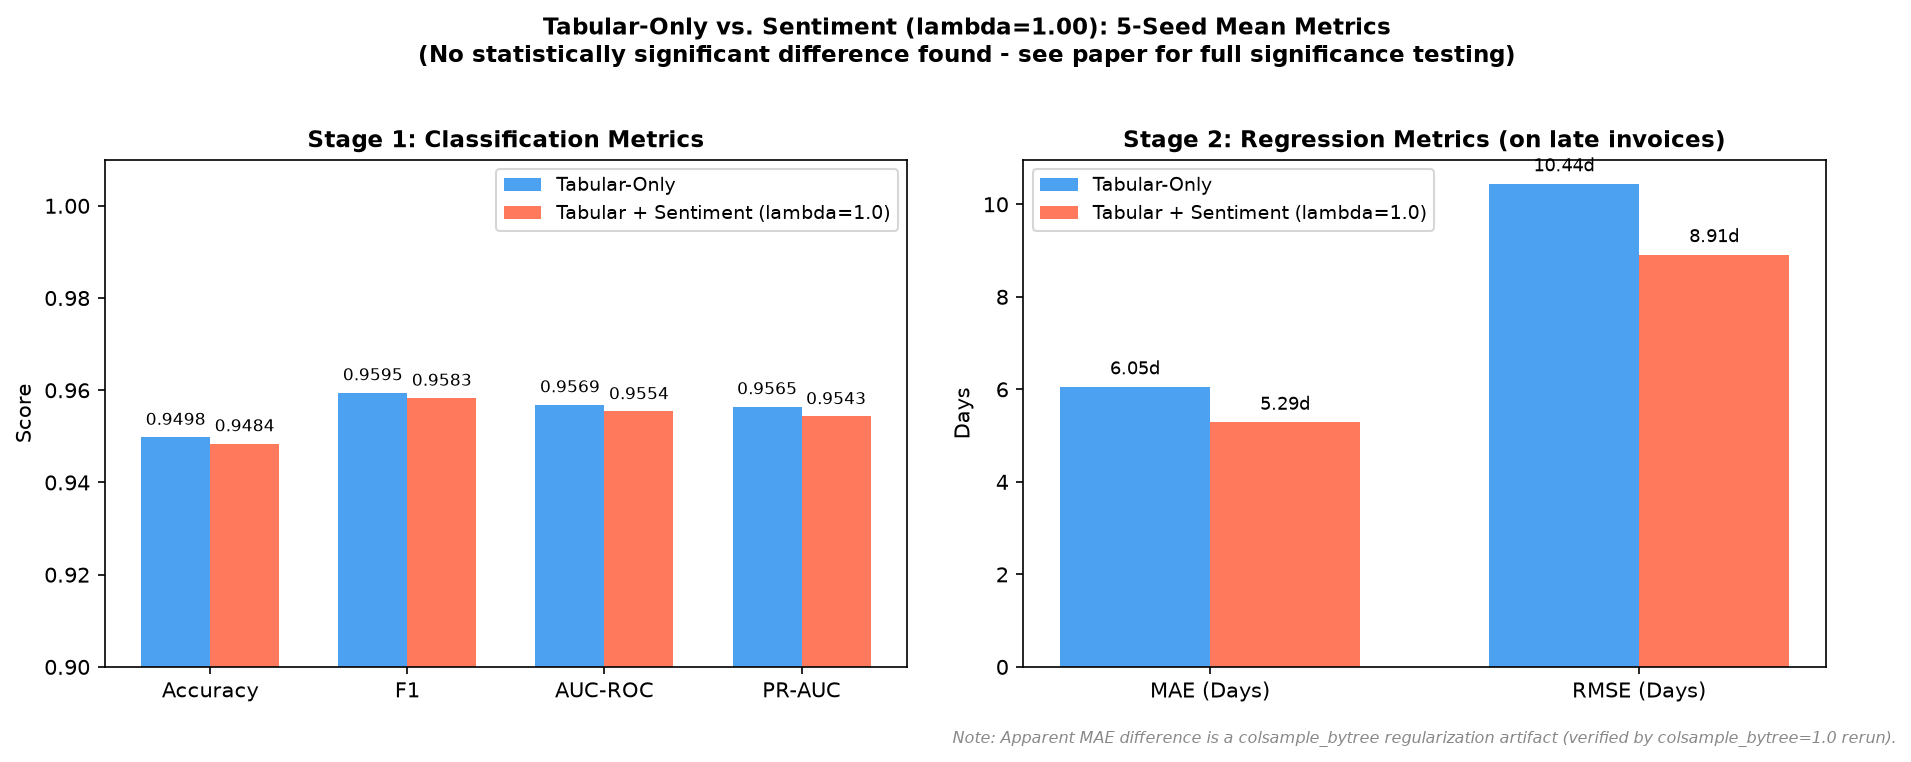

In [8]:
summary_path = PROJECT_ROOT / 'reports' / 'experiment_summary.json'
with open(summary_path, 'r', encoding='utf-8') as f:
    exp_summary = json.load(f)

tab_mean = exp_summary['full_results']['Tabular-Only']['mean_metrics']
tab_std = exp_summary['full_results']['Tabular-Only']['std_metrics']
snt_mean = exp_summary['full_results']['Signal_1.00']['mean_metrics']
snt_std = exp_summary['full_results']['Signal_1.00']['std_metrics']
p_cls = exp_summary['significance_testing']['Signal_1.00']['vs_Tabular_Only']['cluster_tests']['accuracy']['p_value']

comp_df = pd.DataFrame({
    'Metric': ['Accuracy', 'F1-Score', 'AUC-ROC', 'PR-AUC', 'MAE (Days)', 'RMSE (Days)'],
    'Tabular-Only (5-Seed Mean +/- Std)': [
        f"{tab_mean['accuracy']:.4f} +/- {tab_std['accuracy']:.4f}",
        f"{tab_mean['f1']:.4f} +/- {tab_std['f1']:.4f}",
        f"{tab_mean['auc_roc']:.4f} +/- {tab_std['auc_roc']:.4f}",
        f"{tab_mean['pr_auc']:.4f} +/- {tab_std['pr_auc']:.4f}",
        f"{tab_mean['mae']:.2f} +/- {tab_std['mae']:.2f} d",
        f"{tab_mean['rmse']:.2f} +/- {tab_std['rmse']:.2f} d",
    ],
    'CapFlow Multimodal (lambda=1.00)': [
        f"{snt_mean['accuracy']:.4f} +/- {snt_std['accuracy']:.4f}",
        f"{snt_mean['f1']:.4f} +/- {snt_std['f1']:.4f}",
        f"{snt_mean['auc_roc']:.4f} +/- {snt_std['auc_roc']:.4f}",
        f"{snt_mean['pr_auc']:.4f} +/- {snt_std['pr_auc']:.4f}",
        f"{snt_mean['mae']:.2f} +/- {snt_std['mae']:.2f} d",
        f"{snt_mean['rmse']:.2f} +/- {snt_std['rmse']:.2f} d",
    ],
    'Statistical Significance (vs. Tabular)': [
        f"p_cluster = {p_cls:.4f} (Not Significant)",
        'Not Significant',
        'Not Significant',
        'Not Significant',
        'Artifact (colsample dilution + tree distraction)',
        'Artifact (colsample dilution + tree distraction)'
    ]
})
display(comp_df)

# Display clean comparison chart
from IPython.display import Image
img_path = PROJECT_ROOT / 'reports' / 'figures' / 'tabular_vs_sentiment_comparison.png'
display(Image(filename=str(img_path)))

## Phase 5: Feature Importances, Prescriptive Action Directives & Demo System

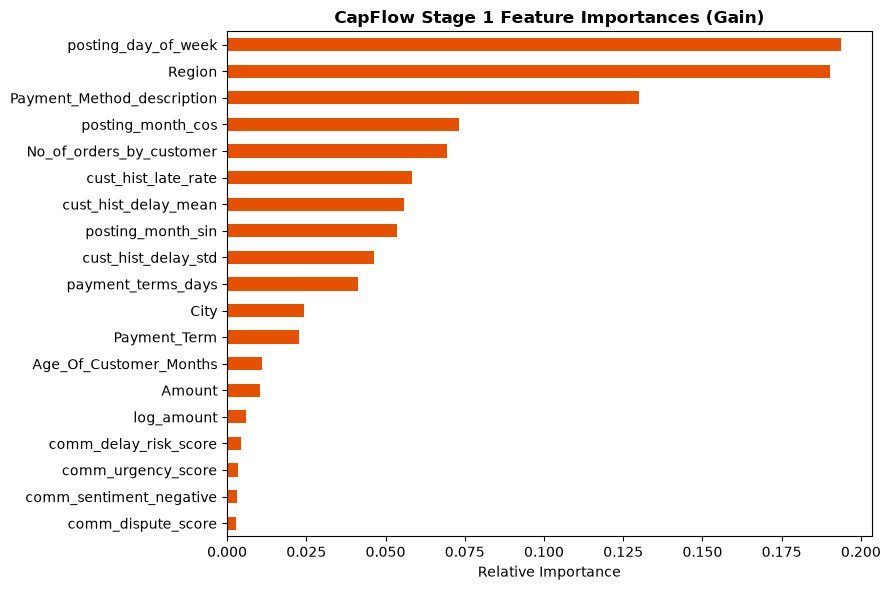

,Customer_ID,Amount,Dispute_Score,Late_Probability,Est_Delay_Days,Prescriptive_Action
0,5039221092,"$64,295.00",0.080,99.84%,2.1 d,REMINDER_SCHEDULED (Short Delay Expected)
1,5039221092,$741.00,0.080,99.76%,2.1 d,REMINDER_SCHEDULED (Short Delay Expected)
2,5039221092,"$2,617.00",0.080,99.80%,2.1 d,REMINDER_SCHEDULED (Short Delay Expected)
3,5039221092,"$24,577.00",0.080,99.82%,2.1 d,REMINDER_SCHEDULED (Short Delay Expected)
4,5039221092,"$1,260.00",0.080,99.79%,2.1 d,REMINDER_SCHEDULED (Short Delay Expected)



To launch the interactive demo application, run:
streamlit run app/demo.py


In [9]:
# 1. Feature Importances
xgb_model = models['CapFlow (XGBoost)']
feat_imp = pd.Series(xgb_model.feature_importances_, index=FULL_FEATURE_SET).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
feat_imp.plot(kind='barh', ax=ax, color='#E65100')
ax.set_title('CapFlow Stage 1 Feature Importances (Gain)', fontsize=12, fontweight='bold')
ax.set_xlabel('Relative Importance')
plt.tight_layout()
plt.show()

# 2. Prescriptive Credit Action Directives
def map_prescriptive_action(late_prob, est_delay, dispute_score):
    if dispute_score > 0.65:
        return 'DISPUTE_RESOLUTION_TEAM (Immediate Commercial Review)'
    elif late_prob < 0.20:
        return 'EXPAND_TERMS (Discount Eligible)'
    elif late_prob < 0.50:
        return 'STANDARD_MONITOR (Low Risk)'
    elif est_delay < 7:
        return 'REMINDER_SCHEDULED (Short Delay Expected)'
    else:
        return 'FACTORING_EXPEDITION (High Default/Delay Risk)'

sample_test = test_nlp.iloc[:5].copy()
sample_p = probas_test['CapFlow (XGBoost)'][:5]
sample_d = np.maximum(0, reg_full.predict(X_test.iloc[:5][FULL_FEATURE_SET]))
sample_disp = sample_test['comm_dispute_score'].values

directive_df = pd.DataFrame({
    'Customer_ID': sample_test[COL_CUSTOMER_ID].values,
    'Amount': sample_test[COL_AMOUNT].values,
    'Dispute_Score': sample_disp,
    'Late_Probability': sample_p,
    'Est_Delay_Days': [d if p >= 0.89 else 0 for p, d in zip(sample_p, sample_d)],
    'Prescriptive_Action': [map_prescriptive_action(p, d, s) for p, d, s in zip(sample_p, sample_d, sample_disp)]
})

display(directive_df.style.format({'Amount': '${:,.2f}', 'Dispute_Score': '{:.3f}', 'Late_Probability': '{:.2%}', 'Est_Delay_Days': '{:.1f} d'}))
print('\nTo launch the interactive demo application, run:')
print('streamlit run app/demo.py')